In [1]:
import pandas as pd

df = pd.read_csv("apollo_data.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1338, 8)
['Unnamed: 0', 'age', 'sex', 'smoker', 'region', 'viral load', 'severity level', 'hospitalization charges']


,Unnamed: 0,age,sex,smoker,region,viral load,severity level,hospitalization charges
0,0,19,female,yes,southwest,9.30,0,42212
1,1,18,male,no,southeast,11.26,1,4314
2,2,28,male,no,southeast,11.00,3,11124
3,3,33,male,no,northwest,7.57,0,54961
4,4,32,male,no,northwest,9.63,0,9667


In [2]:
print(df.columns.tolist())


['Unnamed: 0', 'age', 'sex', 'smoker', 'region', 'viral load', 'severity level', 'hospitalization charges']


In [4]:
df = pd.read_csv("apollo_data.csv", index_col=0)

In [5]:
print(df.shape)
print(df.columns.tolist())
df.head()

(1338, 7)
['age', 'sex', 'smoker', 'region', 'viral load', 'severity level', 'hospitalization charges']


,age,sex,smoker,region,viral load,severity level,hospitalization charges
0,19,female,yes,southwest,9.30,0,42212
1,18,male,no,southeast,11.26,1,4314
2,28,male,no,southeast,11.00,3,11124
3,33,male,no,northwest,7.57,0,54961
4,32,male,no,northwest,9.63,0,9667


In [6]:
df.info()
print("\n--- Numeric summary ---")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      1338 non-null   int64  
 1   sex                      1338 non-null   str    
 2   smoker                   1338 non-null   str    
 3   region                   1338 non-null   str    
 4   viral load               1338 non-null   float64
 5   severity level           1338 non-null   int64  
 6   hospitalization charges  1338 non-null   int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 94.5 KB

--- Numeric summary ---


,age,viral load,severity level,hospitalization charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,10.221233,1.094918,33176.058296
std,14.049960,2.032796,1.205493,30275.029296
min,18.000000,5.320000,0.000000,2805.000000
25%,27.000000,8.762500,0.000000,11851.000000
50%,39.000000,10.130000,1.000000,23455.000000
75%,51.000000,11.567500,2.000000,41599.500000
max,64.000000,17.710000,5.000000,159426.000000


In [7]:
# 4: Missing values + categorical uniques

In [8]:
print("Missing values:\n", df.isnull().sum())
print("\n--- Unique values ---")
print("sex:", df["sex"].unique())
print("smoker:", df["smoker"].unique())
print("region:", df["region"].unique())
print("severity level:", sorted(df["severity level"].unique()))

Missing values:
 age                        0
sex                        0
smoker                     0
region                     0
viral load                 0
severity level             0
hospitalization charges    0
dtype: int64

--- Unique values ---
sex: <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region: <ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str
severity level: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [9]:
# Step 5: Charges by smoker & by region

print("Mean charges by smoker:")
print(df.groupby("smoker")["hospitalization charges"].mean())

print("\nMean charges by region:")
print(df.groupby("region")["hospitalization charges"].mean())

print("\nMean charges by severity level:")
print(df.groupby("severity level")["hospitalization charges"].mean())

Mean charges by smoker:
smoker
no     21085.675752
yes    80125.572993
Name: hospitalization charges, dtype: float64

Mean charges by region:
region
northeast    33515.966049
northwest    31043.941538
southeast    36838.541209
southwest    30867.332308
Name: hospitalization charges, dtype: float64

Mean charges by severity level:
severity level
0    30914.940767
1    31827.935185
2    37683.908333
3    38388.305732
4    34626.680000
5    21965.000000
Name: hospitalization charges, dtype: float64


In [10]:
# Step 6: First formal test — smoker vs non-smoker charges (independent t-test)


In [11]:
from scipy import stats

smoker_yes = df[df["smoker"] == "yes"]["hospitalization charges"]
smoker_no  = df[df["smoker"] == "no"]["hospitalization charges"]

t_stat, p_value = stats.ttest_ind(smoker_yes, smoker_no, equal_var=False)
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.4e}")

t-statistic: 32.7519
p-value:     5.8909e-103


In [12]:
#  Step 7: ANOVA — do mean charges differ across the 4 regions?

In [13]:
regions = [df[df["region"] == r]["hospitalization charges"] for r in df["region"].unique()]
f_stat, p_value = stats.f_oneway(*regions)
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

F-statistic: 2.9696
p-value:     0.0309


In [ ]:
# Interpretation (Baby Step 7)p-value = 0.0309 < 0.05, so we reject the null.

# Mean hospitalization charges differ significantly across the four regions (though the effect is much weaker than smoking).

In [14]:
# Baby Step 8: Chi-square — is smoker status independent of region?

contingency = pd.crosstab(df["smoker"], df["region"])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square: {chi2:.4f}")
print(f"p-value:    {p_value:.4f}")
print(f"dof:        {dof}")

Chi-square: 7.3435
p-value:    0.0617
dof:        3


In [15]:
#Step 9 Chi sqaure- is sex independent of region?

contingency_sex = pd.crosstab(df["sex"], df["region"])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_sex)
print(f"Chi-square: {chi2:.4f}")
print(f"p-value:    {p_value:.4f}")
print(f"dof:        {dof}")

Chi-square: 0.4351
p-value:    0.9329
dof:        3


In [ ]:
# Interpretation (Baby Step 9)p-value ≈ 0.93, so we fail to reject the null.

# Sex is independent of region — the male/female split is essentially the same across all four regions.

In [16]:
# Baby Step 10: ANOVA — does severity level differ across regions?

sev_by_region = [df[df["region"] == r]["severity level"] for r in df["region"].unique()]
f_stat, p_value = stats.f_oneway(*sev_by_region)
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

F-statistic: 0.7175
p-value:     0.5416


In [ ]:
'''
Interpretation (Baby Step 10)p-value ≈ 0.54, so we fail to reject the null.

Average severity level does not differ significantly across the four regions.
'''

# Baby Step 11: ANOVA — does viral load differ across regions?

In [17]:
viral_by_region = [df[df["region"] == r]["viral load"] for r in df["region"].unique()]
f_stat, p_value = stats.f_oneway(*viral_by_region)
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

F-statistic: 39.4687
p-value:     0.0000


In [ ]:
'''    
Interpretation (Baby Step 11)F-statistic is large and p-value ≈ 0.

Viral load does differ significantly across the four regions — this is the strongest regional pattern we have found so far.Quick summary for Question 1 (regions)
Charges differ by region (weak)
Smoker & sex are independent of region
Severity does not differ by region
Viral load differs strongly by region
'''

# Baby Step 12: Prepare for OLS — encode smoker and create a simple model

In [18]:
df["smoker_yes"] = (df["smoker"] == "yes").astype(int)

import statsmodels.api as sm
X = df[["viral load", "smoker_yes", "severity level"]]
X = sm.add_constant(X)
y = df["hospitalization charges"]

model = sm.OLS(y, X).fit()
print(model.summary().tables[1])   # coefficients only

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const          -1.017e+04   2516.430     -4.041      0.000   -1.51e+04   -5232.814
viral load      2899.5968    237.263     12.221      0.000    2434.148    3365.045
smoker_yes      5.895e+04   1194.671     49.345      0.000    5.66e+04    6.13e+04
severity level  1494.0069    400.100      3.734      0.000     709.114    2278.900


In [ ]:
'''Interpretation (Baby Step 12)All three variables are highly significant (p < 0.001):
smoker_yes: +≈59,000 — by far the largest effect
viral load: +≈2,900 per unit
severity level: +≈1,500 per level'''



In [19]:
# Baby Step 13: How good is the model? (R² and overall fit)

print(f"R-squared:     {model.rsquared:.4f}")
print(f"Adj. R-squared:{model.rsquared_adj:.4f}")
print(f"F-statistic:   {model.fvalue:.2f}")
print(f"Prob (F):      {model.f_pvalue:.4e}")

R-squared:     0.6615
Adj. R-squared:0.6607
F-statistic:   868.98
Prob (F):      0.0000e+00


In [20]:
# **Interpretation (Baby Step 13)**

# R² ≈ 0.66 → the three variables together explain about 66% of the variation in hospitalization charges.  
# The model is highly significant overall (p ≈ 0).

# ---

# **Baby Step 14: Quick residual check (is the model reasonable?)**




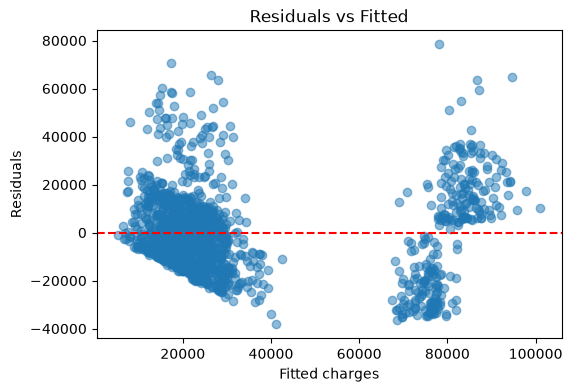

In [21]:
import matplotlib.pyplot as plt

residuals = model.resid
plt.figure(figsize=(6, 4))
plt.scatter(model.fittedvalues, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

In [ ]:
'''Interpretation of the residual plotThe plot shows two clear clusters:
Left cluster (fitted ≈ 10k–40k) → non-smokers
Right cluster (fitted ≈ 70k–100k) → smokers
Within each cluster the residuals are roughly centered around zero. There is no strong curved pattern, so the linear model is acceptable for this data. The separation is expected because smoking has such a large effect.'''

In [22]:
# Baby Step 15: Final small summary of both questions


print("=== Question 1 (Regions) ===")
print("Charges differ by region: p = 0.0309")
print("Viral load differs by region: p ≈ 0")
print("Severity, sex, smoker do NOT differ by region")

print("\n=== Question 2 (Charges) ===")
print(f"R² = {model.rsquared:.3f}")
print("Biggest driver: smoker (+≈59k)")
print("Then viral load and severity level")

=== Question 1 (Regions) ===
Charges differ by region: p = 0.0309
Viral load differs by region: p ≈ 0
Severity, sex, smoker do NOT differ by region

=== Question 2 (Charges) ===
R² = 0.662
Biggest driver: smoker (+≈59k)
Then viral load and severity level


# Apollo Hospitals – Hospitalization Hypothesis Testing

## Assignment
As a data scientist at Apollo Hospitals, analyze anonymized COVID-19 patient data to answer:

1. Which variables are significant in predicting the reason for hospitalization for different regions?
2. How well do viral load, smoking status, and severity level describe hospitalization charges?

Use statistical tests and regression. Show the full thought process, including data preparation.

In [23]:
# Convert categoricals to category type
for col in ["sex", "smoker", "region"]:
    df[col] = df[col].astype("category")

print(df.dtypes)
df.head(3)

age                           int64
sex                        category
smoker                     category
region                     category
viral load                  float64
severity level                int64
hospitalization charges       int64
smoker_yes                    int64
dtype: object


,age,sex,smoker,region,viral load,severity level,hospitalization charges,smoker_yes
0,19,female,yes,southwest,9.30,0,42212,1
1,18,male,no,southeast,11.26,1,4314,0
2,28,male,no,southeast,11.00,3,11124,0


## Question 1 – Regional Patterns

**Results**
- Viral load differs significantly across regions (ANOVA, p ≈ 0).
- Hospitalization charges differ modestly by region (ANOVA, p = 0.031).
- Severity level, sex, and smoker status do **not** differ by region (all p > 0.05).

**Implication for Apollo**  
Viral load is the only clear regional signal. This suggests differences in infection intensity or testing practices across Delhi regions, while patient demographics and severity are relatively uniform.

## Question 2 – Drivers of Hospitalization Charges

**Model**  
OLS: hospitalization charges ~ viral load + smoker + severity level

**Results**
- All three predictors are highly significant (p < 0.001).
- Smoker has the largest effect (+≈ ₹59,000).
- Viral load (+≈ ₹2,900 per unit) and severity level (+≈ ₹1,500 per level) are smaller but still meaningful.
- R² ≈ 0.66 → the model explains about two-thirds of the variation in charges.

**Implication for Apollo**  
Smoking status is the dominant cost driver. Pricing, resource planning, and risk models should treat smokers as a distinct high-cost group.

## Insights and Recommendations

### Key Insights
- **Viral load** is the only variable that differs strongly across Delhi regions.
- **Smoking** is by far the biggest driver of hospitalization charges (+≈ ₹59k).
- Viral load and severity level also raise charges, but the effects are much smaller.
- Sex and severity are uniform across regions; charges differ only modestly by region.

### Recommendations for Apollo
1. Treat smokers as a high-cost segment in pricing and capacity planning.
2. Investigate why viral load varies by region (testing practices, timing of admission, or local outbreak intensity).
3. Use the simple three-variable model as a starting point for cost prediction; it already explains ~66% of the variation.
4. Monitor regional viral-load differences as a possible early signal of uneven disease spread.